# Pune House Rent Prediction

## Data and imports

In [614]:
import kagglehub
path = kagglehub.dataset_download("anantsakhare/rental-price-of-indias-it-capital-pune-mh-ind")

Using Colab cache for faster access to the 'rental-price-of-indias-it-capital-pune-mh-ind' dataset.


In [615]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [616]:
data=pd.read_csv(path + '/train.csv')
df=data.copy()
data.head(3)

,bedroom,bathrooms,area,furnishing,avalable_for,address,floor_number,facing,floor_type,gate_community,...,pooja_room,study_room,others,servant_room,store_room,maintenance_amt,brok_amt,deposit_amt,mnt_amt,rent
0,2,2,1050.0,Unfurnished,All,"Sadguru hights, Pingale Wasti, , Pune, Maharas...",5,West,Marble,Yes,...,0,0,0,0,0,0,0,3,0.0,20000.0
1,2,2,760.0,Unfurnished,All,"Manav Silver Springs, Wagholi, , Pune, Maharas...",5,East,Vitrified,Yes,...,0,0,0,0,0,0,0,40000,0.0,14000.0
2,3,3,0.0,Semifurnished,All,"Saarrthi Souvenir, Mahalunge, , Pune, Maharashtra",1,South-West,Vitrified,Yes,...,0,0,1,0,0,Maintenance 1/ (/ month,23000,60000,1.0,22999.0


## About Data

In [617]:
df.shape

(10884, 30)

In [618]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10884 entries, 0 to 10883
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bedroom            10884 non-null  int64  
 1   bathrooms          10884 non-null  int64  
 2   area               10884 non-null  float64
 3   furnishing         10884 non-null  object 
 4   avalable_for       10854 non-null  object 
 5   address            10884 non-null  object 
 6   floor_number       10884 non-null  int64  
 7   facing             10884 non-null  object 
 8   floor_type         10884 non-null  object 
 9   gate_community     10884 non-null  object 
 10  corner_pro         10884 non-null  object 
 11  parking            10884 non-null  int64  
 12  wheelchairadption  1944 non-null   object 
 13  petfacility        2426 non-null   object 
 14  aggDur             10884 non-null  int64  
 15  noticeDur          10884 non-null  int64  
 16  lightbill          108

In [619]:
df.describe()

,bedroom,bathrooms,area,floor_number,parking,aggDur,noticeDur,lightbill,powerbackup,no_room,pooja_room,study_room,others,servant_room,store_room,brok_amt,deposit_amt,mnt_amt,rent
count,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,10884.000000,1.088400e+04,10884.000000,1.088400e+04
mean,1.797868,1.779677,528.558560,3.062018,0.884693,7.423649,0.722345,0.172639,0.712422,0.750276,0.062201,0.048144,0.124495,0.032157,0.045296,7075.270764,3.670939e+04,257.493025,2.855947e+04
std,0.807328,0.832231,930.460935,2.390430,0.559457,7.670543,0.698966,0.377952,0.842667,0.432873,0.241532,0.214080,0.330160,0.176426,0.207962,17269.507644,5.589578e+04,1247.938097,1.183249e+06
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.600000e+03
25%,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000e+00,0.000000,1.050000e+04
50%,2.000000,2.000000,510.000000,3.000000,1.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000e+04,0.000000,1.500000e+04
75%,2.000000,2.000000,840.000000,5.000000,1.000000,11.000000,1.000000,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9000.000000,5.000000e+04,0.000000,2.100000e+04
max,22.000000,22.000000,72775.000000,9.000000,9.000000,36.000000,6.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,275000.000000,1.500000e+06,40000.000000,1.234568e+08


## Filling and dropping nulls

In [620]:
(df.isnull().sum()/df.shape[0])*100

,0
bedroom,0.000000
bathrooms,0.000000
area,0.000000
furnishing,0.000000
avalable_for,0.275634
address,0.000000
floor_number,0.000000
facing,0.000000
floor_type,0.000000
gate_community,0.000000


In [621]:
# Since column wheelchairadption petfacility
df.drop(columns=['wheelchairadption','petfacility'],inplace=True)

In [622]:
# As we are left with only column with null avalable_for
df['avalable_for'].fillna(df['avalable_for'].mode()[0], inplace=True)
df.rename(columns={'avalable_for': 'available_for'}, inplace=True)

/tmp/ipykernel_2560/645716985.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['avalable_for'].fillna(df['avalable_for'].mode()[0], inplace=True)


In [623]:
df.head(2)

,bedroom,bathrooms,area,furnishing,available_for,address,floor_number,facing,floor_type,gate_community,...,pooja_room,study_room,others,servant_room,store_room,maintenance_amt,brok_amt,deposit_amt,mnt_amt,rent
0,2,2,1050.0,Unfurnished,All,"Sadguru hights, Pingale Wasti, , Pune, Maharas...",5,West,Marble,Yes,...,0,0,0,0,0,0,0,3,0.0,20000.0
1,2,2,760.0,Unfurnished,All,"Manav Silver Springs, Wagholi, , Pune, Maharas...",5,East,Vitrified,Yes,...,0,0,0,0,0,0,0,40000,0.0,14000.0


In [624]:
df.isnull().sum()

,0
bedroom,0
bathrooms,0
area,0
furnishing,0
available_for,0
address,0
floor_number,0
facing,0
floor_type,0
gate_community,0


## Outliers Removal

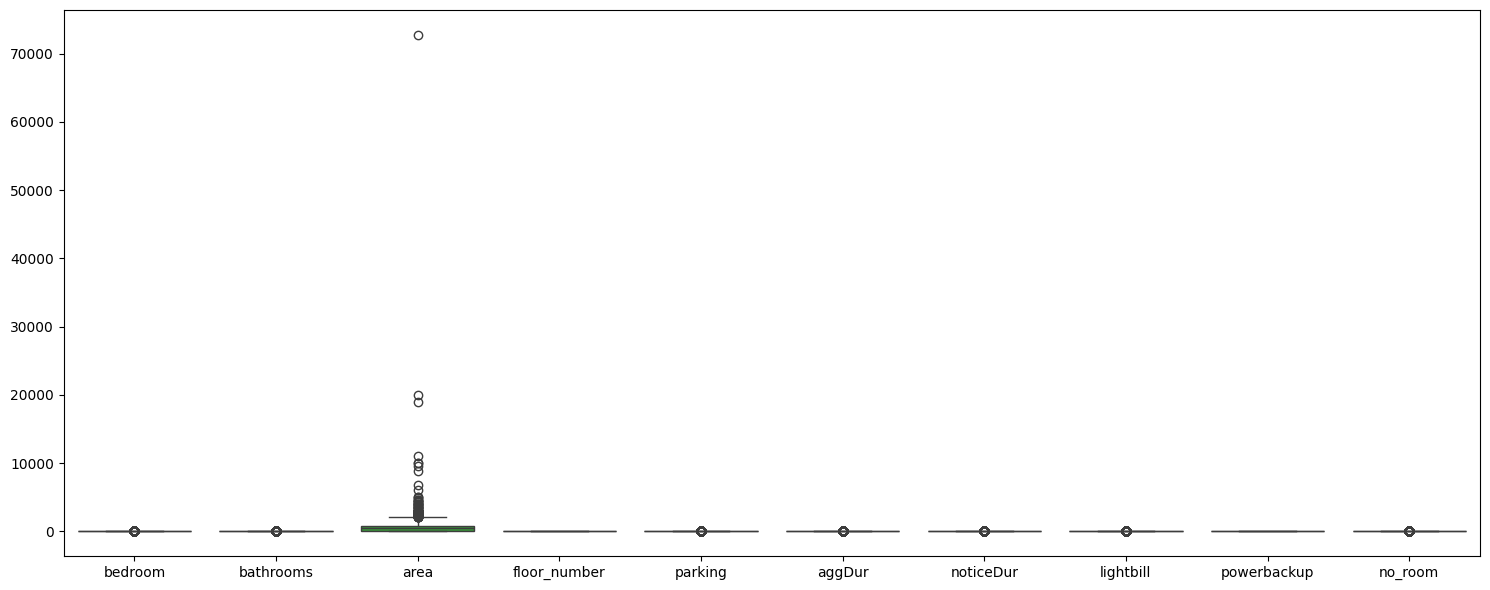

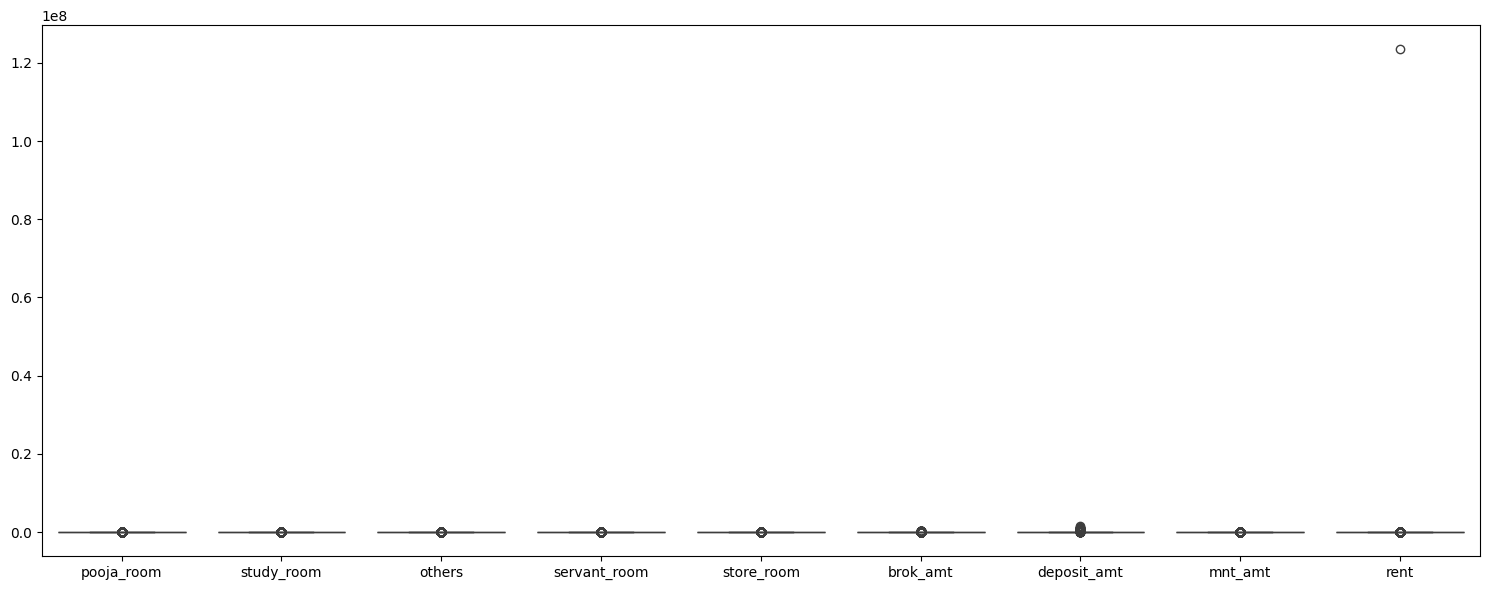

In [625]:
cols=df.select_dtypes('number').columns
for i in range(0,len(cols),10):
  plt.figure(figsize=(15,6))
  sns.boxplot(df[cols[i:i+10]])
  plt.tight_layout()
  plt.show()

In [626]:
df = df[df['area'] > 0].copy()

In [627]:
# removing outlier from area column using IQR
Q1=df['area'].quantile(0.25)
Q3=df['area'].quantile(0.75)
IQR=Q3-Q1
low=Q1-(1.5*IQR)
high=Q3+(1.5*IQR)
df=df[(df['area']>=low) & (df['area']<=high)]
df.shape

(6571, 28)

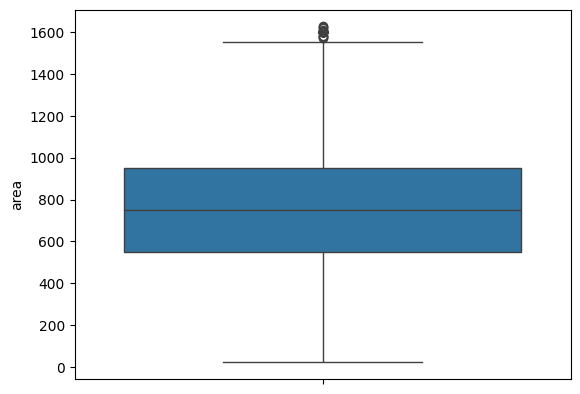

In [628]:
sns.boxplot(df['area'])
plt.show()

## EDA and encoding

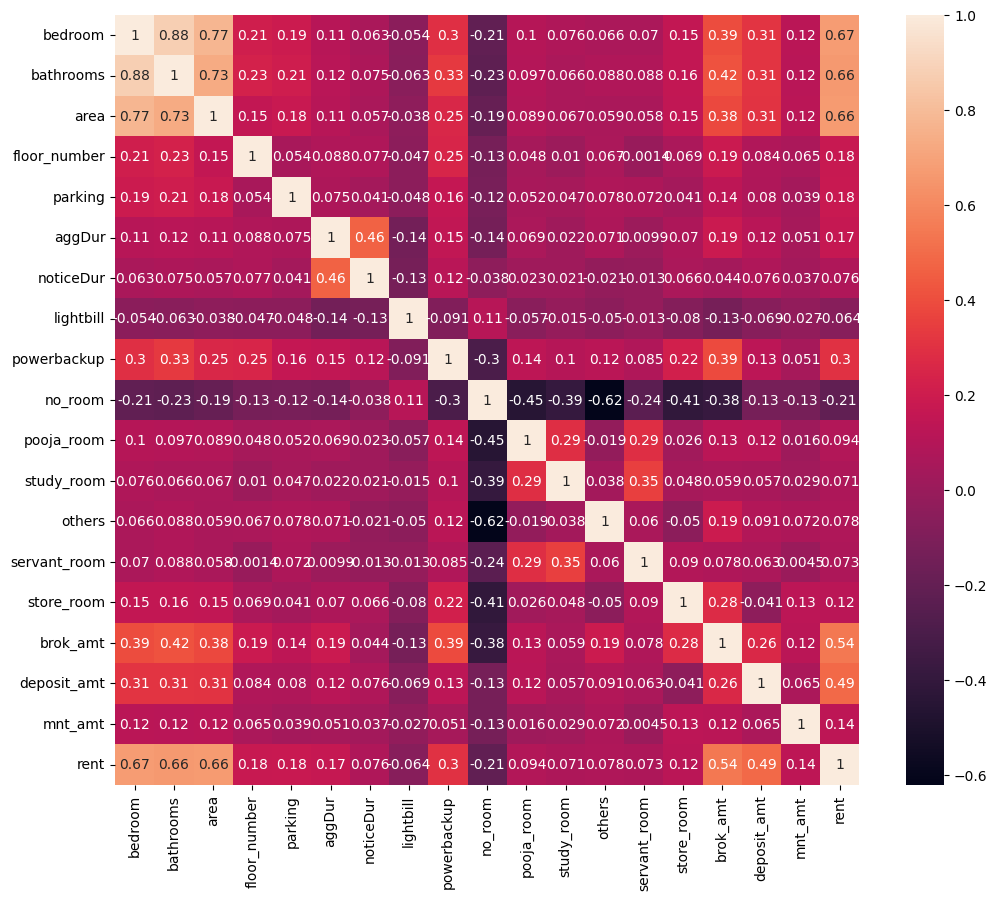

In [629]:
correlation=df.select_dtypes(['int64','float64']).corr()
plt.figure(figsize=(12,10))
sns.heatmap(correlation,annot=True)
plt.show()

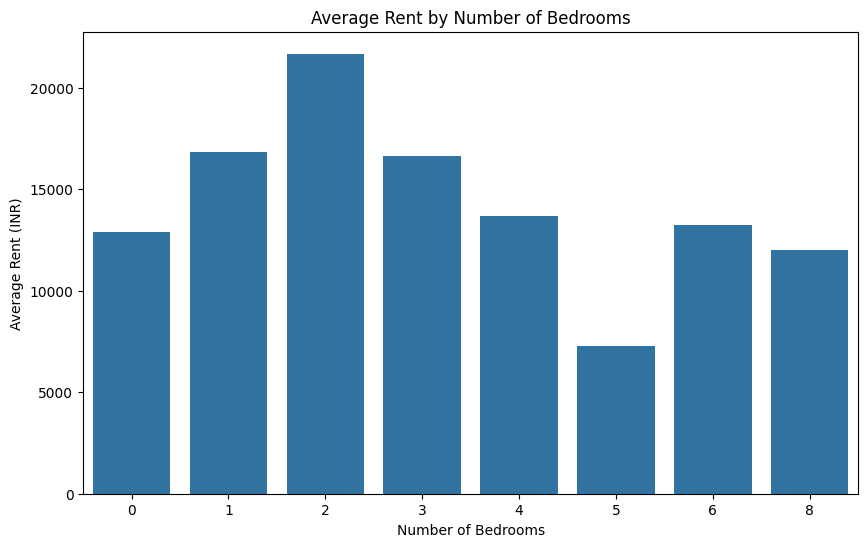

In [630]:
plt.figure(figsize=(10, 6))
sns.barplot(x='parking', y='rent', data=df, errorbar=None)
plt.title('Average Rent by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average Rent (INR)')
plt.show()

In [631]:
df.select_dtypes('object').head()

,furnishing,available_for,address,facing,floor_type,gate_community,corner_pro,propertyage,maintenance_amt
0,Unfurnished,All,"Sadguru hights, Pingale Wasti, , Pune, Maharas...",West,Marble,Yes,No,5 to 10 Year Old,0
1,Unfurnished,All,"Manav Silver Springs, Wagholi, , Pune, Maharas...",East,Vitrified,Yes,Yes,1 to 5 Year Old,0
3,Furnished,Family Only,"Dhan Residency, Wanowrie, , Pune, Maharashtra",East,Mosaic,Yes,No,10+ Year Old,0
4,Semifurnished,"Family , Bachelors (Men Only)","Saptsiddhi Savali Homes, Uruli Devachi, , Pune...",South,Polished concrete,Yes,Yes,1 to 5 Year Old,0
5,Semifurnished,Family Only,"Vimal Apartment, Baner, , Pune, Maharashtra",No Direction,Ceramic,No,No,1 to 5 Year Old,0


In [632]:
df=pd.get_dummies(columns=['furnishing','available_for','facing','floor_type','gate_community','corner_pro'],data=df,dtype=int)
df.head(2)

,bedroom,bathrooms,area,address,floor_number,parking,aggDur,noticeDur,lightbill,powerbackup,...,floor_type_Polished concrete,floor_type_Spartex,floor_type_Stone,floor_type_Vinyl,floor_type_Vitrified,floor_type_Wood,gate_community_No,gate_community_Yes,corner_pro_No,corner_pro_Yes
0,2,2,1050.0,"Sadguru hights, Pingale Wasti, , Pune, Maharas...",5,0,11,2,0,2,...,0,0,0,0,0,0,0,1,1,0
1,2,2,760.0,"Manav Silver Springs, Wagholi, , Pune, Maharas...",5,2,11,1,0,2,...,0,0,0,0,1,0,0,1,0,1


In [633]:
df.select_dtypes('object').head()

,address,propertyage,maintenance_amt
0,"Sadguru hights, Pingale Wasti, , Pune, Maharas...",5 to 10 Year Old,0
1,"Manav Silver Springs, Wagholi, , Pune, Maharas...",1 to 5 Year Old,0
3,"Dhan Residency, Wanowrie, , Pune, Maharashtra",10+ Year Old,0
4,"Saptsiddhi Savali Homes, Uruli Devachi, , Pune...",1 to 5 Year Old,0
5,"Vimal Apartment, Baner, , Pune, Maharashtra",1 to 5 Year Old,0


### Feature Engineering

In [634]:
def addresser(col):
  val=col.split(',')
  if len(val) > 1:
    val=val[1].strip()
  else:
    val=val[0].strip()
  return val

df['address']=df['address'].transform(addresser)

In [635]:
age = []
for i in df['propertyage']:
    if 'Under Construction' in i or 'NO age' in i:
        avg = 0.0
    else:
        val = i.replace(' Year Old', '')
        val = val.replace('+', '')
        val = val.split(' to ')
        if len(val) == 2:
            first = float(val[0].strip())
            last = float(val[1].strip())
            avg = (first + last) / 2.0
        else:
            avg = float(val[0].strip())
    age.append(avg)

df['avg_propertyage'] = pd.DataFrame(age)
df.drop(columns=['propertyage'], inplace=True)
df.head(2)

,bedroom,bathrooms,area,address,floor_number,parking,aggDur,noticeDur,lightbill,powerbackup,...,floor_type_Spartex,floor_type_Stone,floor_type_Vinyl,floor_type_Vitrified,floor_type_Wood,gate_community_No,gate_community_Yes,corner_pro_No,corner_pro_Yes,avg_propertyage
0,2,2,1050.0,Pingale Wasti,5,0,11,2,0,2,...,0,0,0,0,0,0,1,1,0,7.5
1,2,2,760.0,Wagholi,5,2,11,1,0,2,...,0,0,0,1,0,0,1,0,1,3.0


In [636]:
# addres label encoding on the basis of property label using the info from the internet


locality_living_standard = {

    # HIGH / PREMIUM LOCALITIES
    "Koregaon Park": 3,
    "Koregaon Park Annexe": 3,
    "Boat Club Road": 3,
    "Kalyani Nagar": 3,
    "Model Colony": 3,
    "Prabhat Road": 3,
    "Mayur Colony": 3,
    "Rambaug Colony": 3,
    "Bhusari Colony": 3,
    "Aundh": 3,
    "Baner": 3,
    "Baner-Sus": 3,
    "Balewadi": 3,
    "Balewadi Phata": 3,
    "Pashan": 3,
    "Pashan-Sus Road": 3,
    "Viman Nagar": 3,
    "Kothrud": 3,
    "Bavdhan": 3,
    "Magarpatta": 3,
    "Sopan Baug": 3,
    "Sakore Nagar": 3,
    "Sakore Nagar Viman Nagar": 3,
    "Sopan Baug": 3,
    "NIBM": 3,
    "Salunke Vihar": 3,
    "Lullanagar": 3,
    "Sutarwadi": 3,
    "Someshwarwadi": 3,
    "Erandwane": 3,
    "Rambagh Colony": 3,
    "Vishal Nagar": 3,
    "Pimple Nilakh": 3,
    "Pimple Saudagar": 3,
    "Shivtirth Nagar": 3,
    "University Road": 3,
    "Karve Nagar": 3,
    "Shivaji Nagar": 3,
    "Anand Park": 3,
    "Sopan Baug": 3,

    # MEDIUM STANDARD OF LIVING
    "Hadapsar": 2,
    "Hadapsar Gaon": 2,
    "Hadapsar Industrial Estate": 2,
    "Kharadi": 2,
    "Wagholi": 2,
    "Wadgaon Sheri": 2,
    "Vadgaon Sheri": 2,
    "Mundhwa": 2,
    "Keshav Nagar": 2,
    "Manjri": 2,
    "Manjri BK": 2,
    "Manjari Budruk": 2,
    "Manjari Khurd": 2,
    "Wanowrie": 2,
    "Wanwadi": 2,
    "Fatima Nagar": 2,
    "Ghorpadi": 2,
    "Vishrantwadi": 2,
    "Dhanori": 2,
    "Lohegaon": 2,
    "Lohgaon": 2,
    "Yerwada": 2,
    "Tingre Nagar": 2,
    "Dhayari": 2,
    "Warje": 2,
    "Warje Malwadi": 2,
    "Sinhgad Road": 2,
    "Anand Nagar": 2,
    "Ambegaon": 2,
    "Ambegaon Bk": 2,
    "Ambegaon Budruk": 2,
    "Ambegaon Pathar": 2,
    "Bibwewadi": 2,
    "Bibwewadi Kondhwa Road": 2,
    "Bibvewadi Kondhwa Road": 2,
    "Katraj": 2,
    "Katraj Kondhwa Road": 2,
    "Dhankawadi": 2,
    "Parvati Gaon": 2,
    "Parvati Paytha": 2,
    "Dattawadi": 2,
    "Hingne Khurd": 2,
    "Kondhwa": 2,
    "Kondhwa Budruk": 2,
    "Mohamadwadi": 2,
    "Undri": 2,
    "Pisoli": 2,
    "Handewadi": 2,
    "Autadwadi Handewadi": 2,
    "Yewalewadi": 2,
    "Sasane Nagar": 2,
    "Bhekrai Nagar": 2,
    "Phursungi": 2,
    "Manjri": 2,
    "Chandan Nagar": 2,
    "Shastri Nagar": 2,
    "Mhada Colony": 2,
    "Moshi": 2,
    "Bhosari": 2,
    "Pimpri": 2,
    "Pimpri Chinchwad": 2,
    "Pimpri Chinchwad": 2,
    "Chinchwad": 2,
    "Akurdi": 2,
    "Nigdi": 2,
    "Pradhikaran": 2,
    "Ravet": 2,
    "Kiwale": 2,
    "Punawale": 2,
    "Tathawade": 2,
    "Tathvade Udyan": 2,
    "Wakad": 2,
    "Kaspate Vasti": 2,
    "Shankar Kalat Nagar": 2,
    "Rahatani": 2,
    "Thergaon": 2,
    "Kalewadi": 2,
    "Dange Chowk": 2,
    "Pimple Gurav": 2,
    "Pimple Nilakh": 3,
    "Bopodi": 2,
    "Old Sangvi": 2,
    "Pimple Saudagar": 3,
    "Balaji Nagar": 2,
    "Market Yard": 2,
    "Camp": 2,
    "Pune Station": 2,
    "Somwar Peth": 2,
    "Mangalwar Peth": 2,
    "Narayan Peth": 2,
    "Guru Nanak Nagar": 2,
    "Mukund Nagar": 2,
    "Siddharth Nagar": 2,
    "Pragati Nagar": 2,
    "Ashoka Nagar": 2,
    "Sahyadri Park Kondhwa": 2,
    "Tulaja Bhawani Nagar": 2,
    "Keshav Nagar Mundhwa": 2,
    "Eon Free Zone": 2,
    "Maan": 2,
    "Hinjewadi": 2,
    "Hinjewadi Phase 1": 2,
    "Hinjewadi Phase 2": 2,
    "Hinjewadi Phase 3": 2,
    "Phase-3 Hinjewadi": 2,
    "Hinjawadi Phase 1": 2,
    "Hinjewadi Phase-II": 2,
    "Phase-II": 2,
    "Bhukum": 2,
    "Bhugaon": 2,
    "Mahalunge": 2,
    "Sus": 2,
    "Pashan Sus Road": 3,
    "Pirangut": 2,
    "Talegaon": 2,
    "Talegaon Dabhade": 2,
    "Gahunje": 2,
    "Chakan": 2,
    "Uruli Kanchan": 2,
    "Loni Kalbhor": 2,
    "Shewalewadi": 2,
    "Manjari": 2,
    "Wadgaon Budruk": 2,
    "Sutarwadi": 3,
    "Warje Malwadi": 2,
    "Shivane": 2,
    "Dighi": 2,
    "Charholi": 2,
    "Talawade": 2,
    "Alandi": 2,
    "Kharabwadi": 2,
    "Varale": 2,
    "Somatne Phata": 2,
    "Baramati": 2,

    # LOW / DEVELOPING / MORE AFFORDABLE LOCALITIES
    "Uruli Devachi": 1,
    "Yewalewadi": 2,
    "Tapkir Nagar": 1,
    "Dattanagar": 1,
    "Pingale Wasti": 2,
    "Mamta Nagar": 1,
    "Kad Nagar": 1,
    "Mallik Nagar": 1,
    "Nigade Nagar": 1,
    "Bhagwan Nagar": 1,
    "Sudarshan Nagar": 2,
    "Swatantrya Sainik Nagar": 2,
    "Vishnu Dev Nagar": 1,
    "Godwale Vasti": 1,
    "Gulab Nagar": 1,
    "Tukai Nagar": 1,
    "Tukai Darshan": 1,
    "Ambedkar Nagar": 1,
    "Shivnagar Chirke Colony": 1,
    "Raghavendra Nagar": 2,
    "Siddartha Nagar": 1,
    "Shanti Nagar": 2,
    "Balaji Uddyam Nagar": 1,
    "Bhat Nagar": 1,
    "Kamgar Nagar": 1,
    "Tukaram Nagar": 2,
    "Vallabh Nagar": 2,
    "Rupeenagar": 1,
    "Masulkar Colony": 2,
    "Sector-6 Moshi": 2,
    "Sector No-4 Moshi": 2,
    "Sector No-27 Pradhikaran": 2,
    "Sector No-27A Pradhikaran": 2,
    "Sector-29 Ravet": 2,
    "Walhekarwadi": 2,
    "Shahunagar": 2,
    "Laxman Nagar": 2,
    "Krushnaraj Colony": 1,
    "Vijay Vihar": 1,
    "Pandhari Nagar": 1,
    "Prajakta Housing Society": 2,
    "Shitole Nagar": 2,
    "Sant Nagar": 2,
    "Mohanwadi": 2,
    "Vaiduwadi": 2,
    "Laxmi Vihar": 2,
    "Postal Colony": 2,
    "Sainikwadi": 2,
    "Khandve Nagar": 2,
    "Pathare Wasti": 2,
    "Bhunde Vasti": 1,
    "Sangharsh Chowk": 2,
    "Nandel Fata": 1,
    "Nigdi": 2,
    "Kasar Amboli": 2,
    "Loni Kalbhor": 2,
    "Lonikand": 1,
    "Kharabwadi": 1,
    "Kharadi Road": 2,
    "Pune Nagar Road": 2,
    "Lohgaon Dhanori Road": 2,
    "Dhanori Road": 2,
    "B.T. Kawade Road": 2,
    "Katraj": 2,
    "Kondhwa Budruk": 2,
    "NIBM": 3,
    "Mangal Das Road": 2,
    "Wakad Kaspate Road": 2,
    "Dhanukar Colony": 3,
    "Ramkrishna Paramhans Nagar": 3,
    "Niranjan Park": 3,
    "Jadhav Rao Industrial Estate": 1,
    "Bhosalenagar": 3,
    "Madhav Nagar": 2,
    "Yashwant Nagar": 2,
    "Vitthal Nagar": 2,
    "Power House": 2,
    "Wakdewadi": 2,
    "Khese Park": 2,
    "Giridhar Nagar": 2,
    "Abhinav Nagar": 2,
    "Siddharth Nagar": 2,
    "Shivaji Nagar": 3,
    "Nawazish Park Society": 2,
    "Meera Nagar": 3,
    "Madhuban Society": 2,
    "Sahwas Society": 2,
    "Sahyadri Park": 2,
    "Laxmi-Narayan Nagar": 2,
    "Ashoka Nagar": 2,
    "Balaji Nagar": 2,
    "Vasant Vihar": 2,
    "Tingre Nagar": 2,
    "Lane No. 11": 2,
    "Near HDFC Bank Lane": 2,
    "LC Fitness Club": 2,
    "Behind Bharati Vidyapeeth": 2,
    "Bharati Vidyapeeth": 2,
    "Mhada Colony": 2,
    "Waghere Colony No. 4": 2,
    "Siddharth Nagar": 2,
    "Ideal Colony": 3,
    "J. M Road": 3,
    "Kalyani Nagar Rd": 3,
    "PAUD ROAD KOTHRUD": 3,
    "Koregaon Park Lane 7": 3,
    "Samartha Colony Baner": 3,
    "Vishal Nagar pimple Nilakh": 3,
    "Divine Home Lohagoan": 2,
    "Prathamesh Park": 2,
    "Kondhawe Dhawade": 2,
    "Venkatesh Lake Life": 2,
    "Bhekarai nagar": 2,
    "Shrikrishna housing society": 2,
    "Sai Heme Medaows": 2,
    "Wadeshwar Nagar": 2,
    "tushar park": 2,
    "Bhavani Super market": 2,
    "Vishal Nagar pimple Nilakh": 3,
    "Raghav Nagar": 2,
    "rajiv gandhi infotec park hinjewadi": 2,
    "Anand nagar": 3,
    "NIBM Pune": 3,
    "bhosale village": 2,
    "Pimpri Waghwere": 2,
    "Macdonalds Rainbow Crossword Wagholi Pune": 2,
    "Sinhagad Road": 2,
    "Jarande Nagar": 2,
    "Urit Nagar": 2,
    "Wakad Annexe": 2,
    "Sitaphal Baug Colony": 2,
    "vadgaonsheri": 2,
    "New Mahada Colony": 2,
    "Seva Nagar": 2,
    "Rajiv Nagar North": 2,
    "Mahamadwadi khind": 2,
    "Dhanori Gaothan": 2,
    "Hanuman. Nagar Mundhwa": 2,
    "Samarth Colony": 2,
    "Kothrud City Pride": 3,
    "Sadasatara Nali": 2,
    "Nehru Nagar Road": 2,
    "Tingle Nagar": 2,
    "Sai Shradha Colony": 2,
    "Mantra Insignia": 2,
    "Keshav Nagar Chinchwad": 2,
    "Near Wadgaon Budruk Busstop": 2,
    "Sector-25 Pradhikaran": 2,
    "wagholi": 2,
    "suvarnyoug colony": 2,
    "Vittalvadi": 2,
    "Shivaji Park": 2,
    "Rambaug colony": 3,
    "pride world city charoli": 2,
    "Kunjir Colony": 2,
    "Navshydri": 2,
    "Baliraj Colony Rahatni": 2,
    "Sai Nagar": 2,
    "Gangadham": 2,
    "Arihant Apartment": 2,
    "Sinhgad College Road": 2,
    "old sanghavi": 2,
    "Near Z Corner": 2,
    "Anandnager": 2,
    "Jai Prakash Nagar": 2,
    "Aboli Villa": 2,
    "Vakil Nagar": 2,
    "Near Darshan Hall": 2,
    "Katey Basti": 2,
    "Dudhane Nagar": 2,
    "Deccan Gymkhana": 3,
    "S. No 122 kalas malvadi road": 2,
    "Near JSPM college": 2,
    "Opposite Indira School": 2,
    "Satavwadi": 2,
    "Ganga Park Near Passport Office": 2,
    "Pratiksha building": 2,
    "Bijlinagar": 2,
    "Dedge industrial estate": 2,
    "Pride World City": 2,
    "Prati shirdi sai mandir": 2,
    "Yashwant nagar": 2,
    "Near Omkar mitramandal": 2,
    "Shiv Nagar": 2,
    "Kharadi Bypass": 2,
    "Udyognagar": 2,
    "Shikshaknagar": 2,
    "sai balaji enclave kharadi": 2,
    "Near Lotus Hospital": 2,
    "Ganesh Nagar Lane-2": 2,
    "Shirish Tendulkar Chowk": 2,
    "adharsh nagar kiwale dehuroad": 2,
    "Laxmi colony": 2,
    "Jagdish Nagar": 2,
    "Indrayani Nagar Sector 2": 2,
    "Dhayarigoan": 2,
    "Padmaguru Colony": 2,
    "Kalyani Nagar Rd": 3,
    "Rahatani Nakhate Vasti": 2,
    "Shridharnagar": 2,
    "BhekraiNagar": 2,
    "keshav nagar.": 2,
    "dattawadi": 2,
    "Aster Homes": 2,
    "Awhalwadi": 2,
    "Jawalkar Nagar": 2,
    "Dalvinagar": 2,
    "Near Alphonso High School": 2,
    "Karambhumi Nagar": 2,
    "trimurti colony": 2,
    "Pawna Nagar": 2,
    "NDA Road": 2,
    "Near Shradha hospital keshav nagar mundhwa pune 36": 2,
    "Near Ram Krishna mangal karyalaya": 2,
    "Nibm": 3,
    "Nigdi Gaothan": 2,
    "Mankar Chowk": 2,
    "pune hadpsar manjari": 2,
    "karve nagar": 3,
    "navnath nagar suvarna garud society": 2,
    "Sindhi Colony": 2,
    "Yojana Nagar": 2,
    "Ganesh Nagar Wadgaosheri": 2,
    "pune 14": 2,
    "Bhumkar Chowk": 2,
    "Ambre colony": 2,
    "Bijali Nagar": 2,
    "Sanmitra Colony": 2,
    "Baliraj Colony": 2,
    "Salunke Vhar Road": 2,
    "D P Road": 2,
    "Swargate": 2,
    "MIT college": 2,
    "Kadolkar colony": 2,
    "Mirajkar house": 2,
    "Ghorpade Peth": 2,
    "pawna nagar pimplegurav": 2,
    "baner road": 3,
    "Sai Shradha Park": 2,
    "Armut": 2,
    "Prabhat Nagar": 3,
    "lane no. 1": 2,
    "Padmavati mandir": 2,
    "kaspatewasti": 2,
    "Marungi road Laxmi Chowk": 2,
    "Opp. To Thopte Lawn": 2,
    "Karegaon": 1,
    "Chovisawadi": 1,
    "Somatane Phata": 1,
    "Chimbali": 1,
    "Kolwadi": 1,
    "Kasarsai": 1,
    "Bhilarewadi": 1,
    "Mangdewadi": 1,
    "Jambhul": 1,
    "Shiraswadi": 1,
    "Vadgaon Maval": 1,
    "Dehu": 1,
    "Talegaon Dabhade Yashwantnagar": 1,
    "Shindewadi": 1,
    "fursungi": 2,
    "Paud Gaon": 2,
}

df['address']=df['address'].map(locality_living_standard)
df.dropna()
df.head(2)

,bedroom,bathrooms,area,address,floor_number,parking,aggDur,noticeDur,lightbill,powerbackup,...,floor_type_Spartex,floor_type_Stone,floor_type_Vinyl,floor_type_Vitrified,floor_type_Wood,gate_community_No,gate_community_Yes,corner_pro_No,corner_pro_Yes,avg_propertyage
0,2,2,1050.0,2.0,5,0,11,2,0,2,...,0,0,0,0,0,0,1,1,0,7.5
1,2,2,760.0,2.0,5,2,11,1,0,2,...,0,0,0,1,0,0,1,0,1,3.0


In [637]:
# for the maintainance amount column the maintainence amount is not an important feature for deciding the house rent so
df.drop(columns=['maintenance_amt'],inplace=True)

## Visualization

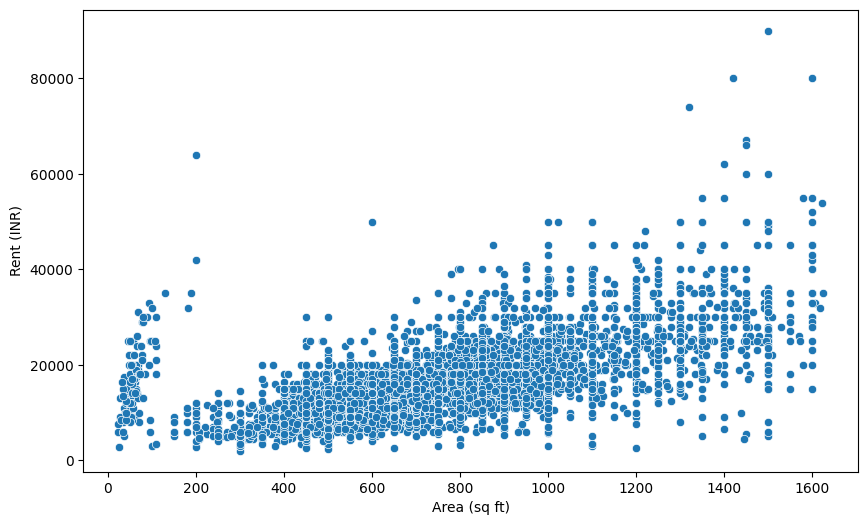

In [638]:
# Plotting Area vs Rent filtering out extreme rent outliers for a clear visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(x='area', y='rent', data=df[df['rent'] < 150000])
plt.xlabel('Area (sq ft)')
plt.ylabel('Rent (INR)')
plt.show()

## model training and testing

In [639]:
from sklearn.model_selection import train_test_split

In [640]:
# 1. Remove extreme target outliers from our cleaned dataset
df_final = df[df['rent'] < 150000].dropna()

X= df_final.drop(columns=['rent'])
y = df_final['rent']

# 2. Correctly Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 3. Correctly Scale
sc_f = StandardScaler()
X_train_scaled = sc_f.fit_transform(X_train)
X_test_scaled = sc_f.transform(X_test)

# 4. Fit and score the model
model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("R^2 Score:", model.score(X_test_scaled, y_test))

R^2 Score: 0.6654327751579738


### model evaluation

In [641]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error
print("MSE")
print(mean_squared_error(model.predict(X_test_scaled)))
print("MAE")
print(mean_absolute_error(model.predict(X_test_scaled)))
print("RMSE")
print(root_mean_squared_error(model.predict(X_test_scaled)))

MSE


TypeError: missing a required argument: 'y_pred'

### pred visualization

In [ ]:
plt.scatter(y_test,model.predict(X_test_scaled))
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],color='red')
plt.show()

### prediction

In [ ]:
print("model prediction:",model.predict([X_test_scaled[10]]))
print("actual answer:",y_test.iloc[10])